<a href="https://colab.research.google.com/github/balavardhansai/ML/blob/main/101_ThotaBalavardhansai_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Imports and configuration

In [ ]:
import os, glob, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score, classification_report, confusion_matrix,
    mean_absolute_error, mean_squared_error, r2_score,
    silhouette_score
)
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.cluster import MiniBatchKMeans

RANDOM_STATE = 42
ROWS_PER_FILE = 250_000
MAX_WORKING_ROWS = 500_000
N_CLUSTERS = 5

np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13})
print("Imports and configuration ready.")

Imports and configuration ready.


## 2. Find and inspect input files

In [ ]:
SEARCH_ROOTS = ["/kaggle/input", "/kaggle/working"]
csv_files = []
for root in SEARCH_ROOTS:
    if os.path.exists(root):
        csv_files.extend(glob.glob(os.path.join(root, "**", "*.csv"), recursive=True))

csv_files = sorted({
    p for p in csv_files
    if os.path.isfile(p) and os.path.getsize(p) > 10_000
})
print("CSV files found:", len(csv_files))
for p in csv_files[:40]:
    print(f"{os.path.getsize(p)/1e6:8.2f} MB | {p}")

if not csv_files:
    raise FileNotFoundError(
        "No usable CSV found. In Kaggle, use Add Input to attach the NYC Yellow Taxi dataset."
    )

CSV files found: 7
 1985.96 MB | /kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2015-01.csv
 1708.67 MB | /kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2016-01.csv
 1783.55 MB | /kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2016-02.csv
 1914.67 MB | /kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2016-03.csv
    0.33 MB | /kaggle/working/pillar_A_validation_predictions.csv
    3.27 MB | /kaggle/working/pillar_B_validation_predictions.csv
    2.98 MB | /kaggle/working/pillar_C_corridor_clusters.csv


## 3. Load a bounded sample

In [ ]:
frames = []
for file_path in csv_files:
    try:
        part = pd.read_csv(file_path, nrows=ROWS_PER_FILE, low_memory=False)
        if len(part):
            part["__source_file"] = os.path.basename(file_path)
            frames.append(part)
            print(os.path.basename(file_path), part.shape)
    except Exception as exc:
        print("Skipped:", file_path, "|", str(exc)[:250])

if not frames:
    raise RuntimeError("CSV candidates were found, but none could be read.")

raw_df = pd.concat(frames, ignore_index=True, sort=False)
if len(raw_df) > MAX_WORKING_ROWS:
    raw_df = raw_df.sample(MAX_WORKING_ROWS, random_state=RANDOM_STATE)

df = raw_df.copy()
df.columns = [str(c).strip() for c in df.columns]
print("Working data shape:", df.shape)
display(df.head())

yellow_tripdata_2015-01.csv (250000, 20)
yellow_tripdata_2016-01.csv (250000, 20)
yellow_tripdata_2016-02.csv (250000, 20)
yellow_tripdata_2016-03.csv (250000, 20)
pillar_A_validation_predictions.csv (82436, 3)
pillar_B_validation_predictions.csv (82436, 3)
pillar_C_corridor_clusters.csv (22789, 12)
Working data shape: (500000, 36)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,RateCodeID,store_and_fwd_flag,dropoff_longitude,...,dropoff_zone,trip_count,mean_distance,mean_duration,mean_pickup_hour,peak_hour_ratio,pickup_frequency,dropoff_frequency,log_trip_count,cluster
246268,1.0,2015-01-14 22:31:07,2015-01-14 22:40:00,1.0,1.40,0.000000,0.000000,1.0,N,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
609201,2.0,2016-02-01 09:28:48,2016-02-01 09:43:58,1.0,1.96,-73.968651,40.763691,NaN,N,-73.993370,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
543131,2.0,2016-02-19 22:35:56,2016-02-19 22:53:30,1.0,4.65,-73.999901,40.717899,NaN,N,-73.955093,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
363984,1.0,2016-01-01 02:40:13,2016-01-01 02:45:30,2.0,1.20,-73.950287,40.779804,NaN,N,-73.938400,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
955046,2.0,2016-03-01 11:50:22,2016-03-01 12:07:59,1.0,1.95,-73.969727,40.768890,NaN,N,-73.990417,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Validate and clean the taxi data

In [ ]:
# Standard NYC Yellow Taxi column names expected by this notebook.
required_cols = [
    "tpep_pickup_datetime", "tpep_dropoff_datetime",
    "trip_distance", "fare_amount"
]
missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise KeyError(
        f"Missing required columns: {missing_cols}. Available columns: {df.columns.tolist()}"
    )

for c in ["tpep_pickup_datetime", "tpep_dropoff_datetime"]:
    df[c] = pd.to_datetime(df[c], errors="coerce")

numeric_cols = [
    "trip_distance", "fare_amount", "passenger_count",
    "PULocationID", "DOLocationID"
]
for c in numeric_cols:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

before = len(df)
df = df.dropna(subset=required_cols).copy()
df = df[(df.trip_distance > 0) & (df.fare_amount > 0)].copy()
df["trip_duration_min"] = (
    df.tpep_dropoff_datetime - df.tpep_pickup_datetime
).dt.total_seconds() / 60
df = df[
    df.trip_duration_min.between(1, 240)
    & df.trip_distance.between(0.1, 100)
].copy()

if "passenger_count" not in df.columns:
    df["passenger_count"] = 1
df["passenger_count"] = df["passenger_count"].fillna(1).clip(1, 6)

print(f"Rows before cleaning: {before:,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Rows removed:         {before-len(df):,}")
display(df[required_cols + ["trip_duration_min"]].describe().T)

Rows before cleaning: 500,000
Rows after cleaning:  415,929
Rows removed:         84,071


,count,mean,min,25%,50%,75%,max,std
tpep_pickup_datetime,415929,2015-10-31 11:09:56.969802752,2015-01-01 00:09:45,2016-01-01 00:02:47,2016-02-01 08:12:26,2016-03-01 00:02:25,2016-03-10 14:55:39,NaN
tpep_dropoff_datetime,415929,2015-10-31 11:23:08.054552320,2015-01-01 00:13:10,2016-01-01 00:10:05,2016-02-01 08:22:04,2016-03-01 00:11:07,2016-03-10 16:16:52,NaN
trip_distance,415929.0,2.962231,0.1,1.0,1.7,3.2,99.9,3.565625
fare_amount,415929.0,12.563467,0.01,6.5,9.5,14.5,360.0,10.32528
trip_duration_min,415929.0,13.184746,1.0,6.483333,10.7,17.116667,237.0,9.684613


## 5. Feature engineering

In [ ]:
df["pickup_hour"] = df.tpep_pickup_datetime.dt.hour
df["pickup_weekday"] = df.tpep_pickup_datetime.dt.dayofweek
df["pickup_month"] = df.tpep_pickup_datetime.dt.month
df["is_weekend"] = (df.pickup_weekday >= 5).astype(int)
df["is_peak_hour"] = (
    df.pickup_hour.between(7, 10) | df.pickup_hour.between(16, 19)
).astype(int)
df["fare_per_mile"] = df.fare_amount / df.trip_distance.clip(lower=0.1)
df["duration_per_mile"] = df.trip_duration_min / df.trip_distance.clip(lower=0.1)
df["is_weekday"] = (df.pickup_weekday < 5).astype(int)

print("Engineered features created.")
display(df[[
    "pickup_hour", "pickup_weekday", "trip_distance",
    "fare_per_mile", "trip_duration_min", "passenger_count"
]].head())

Engineered features created.


,pickup_hour,pickup_weekday,trip_distance,fare_per_mile,trip_duration_min,passenger_count
246268,22,2,1.40,5.714286,8.883333,1.0
609201,9,0,1.96,5.612245,15.166667,1.0
543131,22,4,4.65,3.655914,17.566667,1.0
363984,2,4,1.20,5.000000,5.283333,2.0
955046,11,1,1.95,6.153846,17.616667,1.0


## 6. Exploratory data analysis

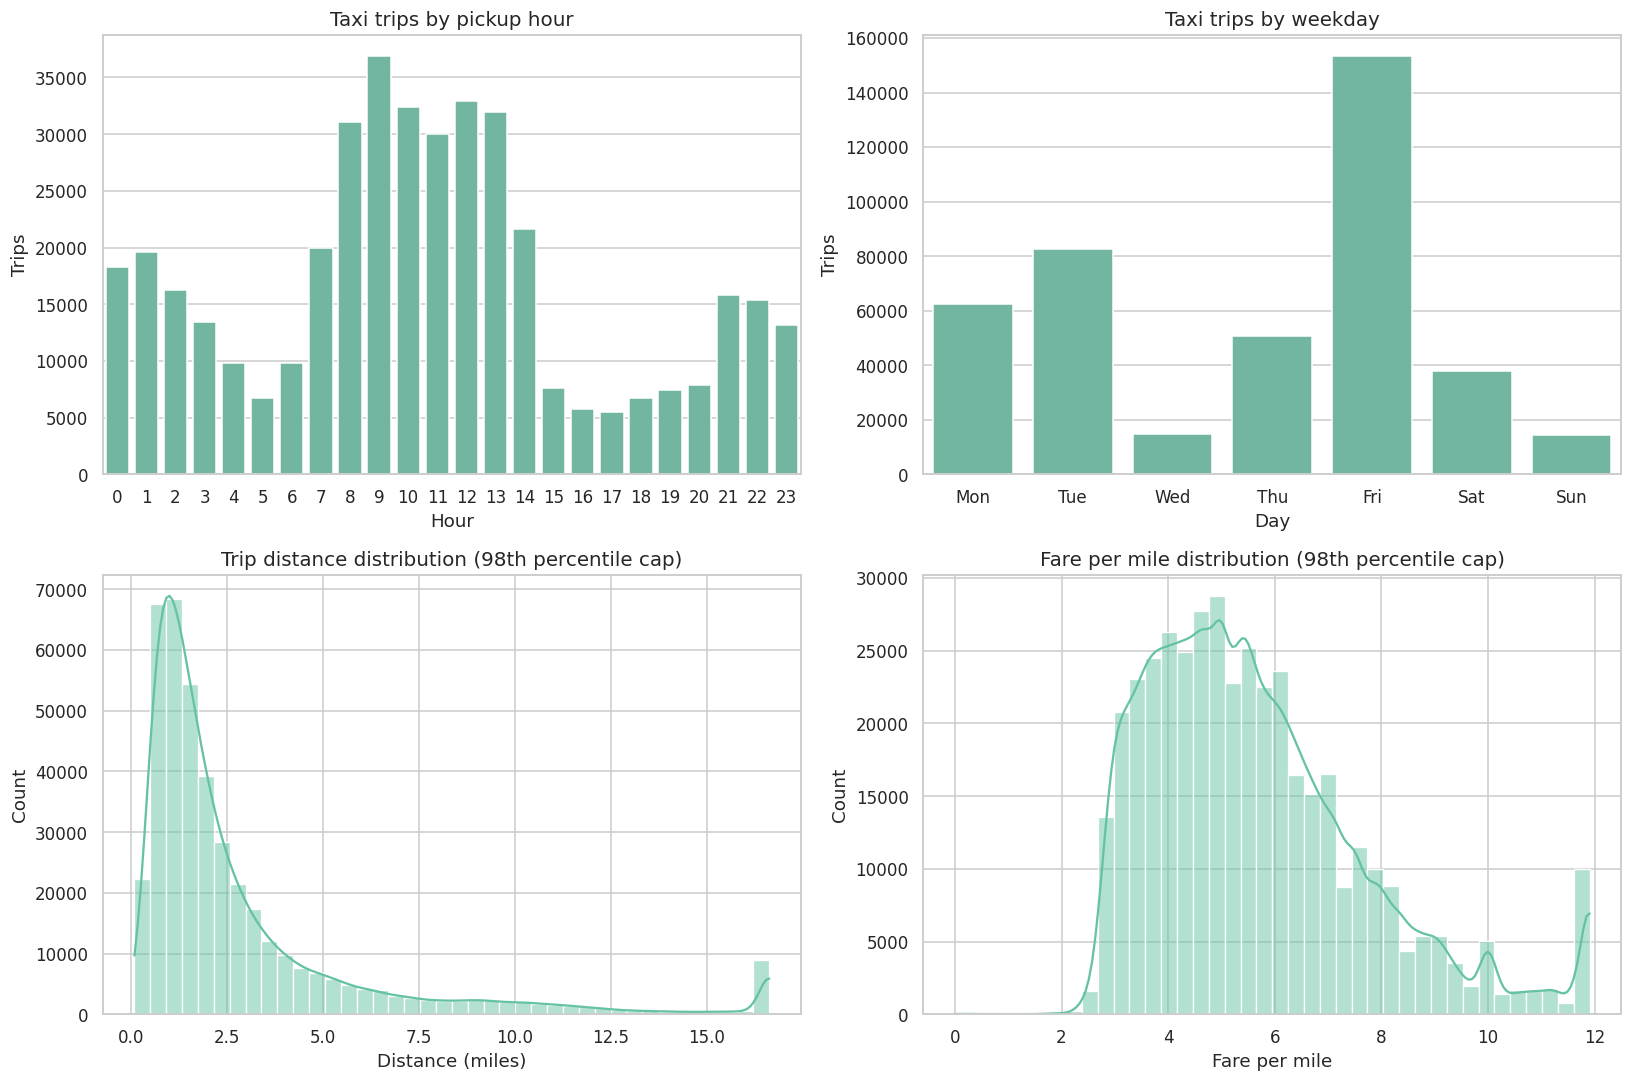

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
hour_counts = df.pickup_hour.value_counts().sort_index()
sns.barplot(x=hour_counts.index, y=hour_counts.values, ax=axes[0,0])
axes[0,0].set(title="Taxi trips by pickup hour", xlabel="Hour", ylabel="Trips")
axes[0,0].set_xticks(range(24))

weekday_counts = df.pickup_weekday.value_counts().reindex(range(7), fill_value=0)
sns.barplot(x=["Mon","Tue","Wed","Thu","Fri","Sat","Sun"],
            y=weekday_counts.values, ax=axes[0,1])
axes[0,1].set(title="Taxi trips by weekday", xlabel="Day", ylabel="Trips")

sns.histplot(df.trip_distance.clip(upper=df.trip_distance.quantile(.98)),
             bins=40, kde=True, ax=axes[1,0])
axes[1,0].set(title="Trip distance distribution (98th percentile cap)",
              xlabel="Distance (miles)", ylabel="Count")

sns.histplot(df.fare_per_mile.clip(upper=df.fare_per_mile.quantile(.98)),
             bins=40, kde=True, ax=axes[1,1])
axes[1,1].set(title="Fare per mile distribution (98th percentile cap)",
              xlabel="Fare per mile", ylabel="Count")
plt.tight_layout()
plt.show()

## 7. Pillar A — Create synthetic surge-tier labels

The brief requires classes **0, 1, 2** using pickup time, weekday, trip distance and fare-to-distance ratio. Since it does not state exact cutoffs, this notebook uses:
- peak-hour flag: 07:00–10:00 or 16:00–19:00;
- weekday flag: Monday–Friday;
- short-trip flag: trip distance at or below the dataset median;
- high fare ratio flag: fare per mile at or above the dataset 75th percentile.

The sum of these four flags is converted to three tiers. These are **our documented synthetic rules**, not an official target formula.

In [ ]:
a_df = df.copy()
distance_threshold = a_df.trip_distance.median()
fare_ratio_threshold = a_df.fare_per_mile.quantile(0.75)

a_df["short_trip_flag"] = (a_df.trip_distance <= distance_threshold).astype(int)
a_df["high_fare_ratio_flag"] = (
    a_df.fare_per_mile >= fare_ratio_threshold
).astype(int)

a_df["surge_rule_score"] = (
    a_df["is_peak_hour"] + a_df["is_weekday"]
    + a_df["short_trip_flag"] + a_df["high_fare_ratio_flag"]
)
a_df["surge_tier"] = np.select(
    [a_df.surge_rule_score <= 1, a_df.surge_rule_score <= 3],
    [0, 1], default=2
).astype(int)

print("Distance median threshold:", round(distance_threshold, 3))
print("Fare/mile 75th percentile threshold:", round(fare_ratio_threshold, 3))
display(a_df.surge_tier.value_counts().sort_index().rename("trip_count").to_frame())

Distance median threshold: 1.7
Fare/mile 75th percentile threshold: 6.716


,trip_count
surge_tier,
0,156668
1,220962
2,38299


## 8. Pillar A — Train and compare four classifiers

In [ ]:
features_A = [
    "pickup_hour", "pickup_weekday", "pickup_month",
    "trip_distance", "fare_per_mile", "is_peak_hour",
    "is_weekend", "passenger_count"
]
X_A = a_df[features_A].replace([np.inf, -np.inf], np.nan)
y_A = a_df["surge_tier"]

X_train_A, X_test_A, y_train_A, y_test_A = train_test_split(
    X_A, y_A, test_size=0.20, random_state=RANDOM_STATE, stratify=y_A
)

classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, random_state=RANDOM_STATE,
                                            class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=160, max_depth=18,
                                            min_samples_leaf=2, n_jobs=-1,
                                            random_state=RANDOM_STATE,
                                            class_weight="balanced_subsample")
}
# HistGradientBoosting does not support sparse preprocessing; use imputer pipeline.
from sklearn.ensemble import HistGradientBoostingClassifier
classifiers["Hist Gradient Boosting"] = HistGradientBoostingClassifier(
    max_iter=160, learning_rate=0.08, max_leaf_nodes=31,
    l2_regularization=1.0, random_state=RANDOM_STATE
)

classification_results = []
classification_models = {}
predictions_A = {}

for name, estimator in classifiers.items():
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler() if name == "Logistic Regression" else "passthrough"),
        ("model", estimator)
    ])
    pipe.fit(X_train_A, y_train_A)
    pred = pipe.predict(X_test_A)
    score = f1_score(y_test_A, pred, average="macro")
    classification_models[name] = pipe
    predictions_A[name] = pred
    classification_results.append({"Model": name, "Macro-F1": score})
    print(f"{name}: Macro-F1 = {score:.4f}")

classification_results = pd.DataFrame(classification_results).sort_values(
    "Macro-F1", ascending=False
).reset_index(drop=True)
display(classification_results)
best_classifier_name = classification_results.iloc[0]["Model"]
best_classifier = classification_models[best_classifier_name]
best_pred_A = predictions_A[best_classifier_name]
macro_f1 = float(classification_results.iloc[0]["Macro-F1"])
print("Best classifier:", best_classifier_name)
print(classification_report(y_test_A, best_pred_A, zero_division=0))

Logistic Regression: Macro-F1 = 0.8634
Decision Tree: Macro-F1 = 1.0000
Random Forest: Macro-F1 = 1.0000
Hist Gradient Boosting: Macro-F1 = 1.0000


,Model,Macro-F1
0,Decision Tree,1.000000
1,Random Forest,1.000000
2,Hist Gradient Boosting,1.000000
3,Logistic Regression,0.863365


Best classifier: Decision Tree
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     31334
           1       1.00      1.00      1.00     44192
           2       1.00      1.00      1.00      7660

    accuracy                           1.00     83186
   macro avg       1.00      1.00      1.00     83186
weighted avg       1.00      1.00      1.00     83186



## 9. Pillar A — Model comparison and confusion matrix

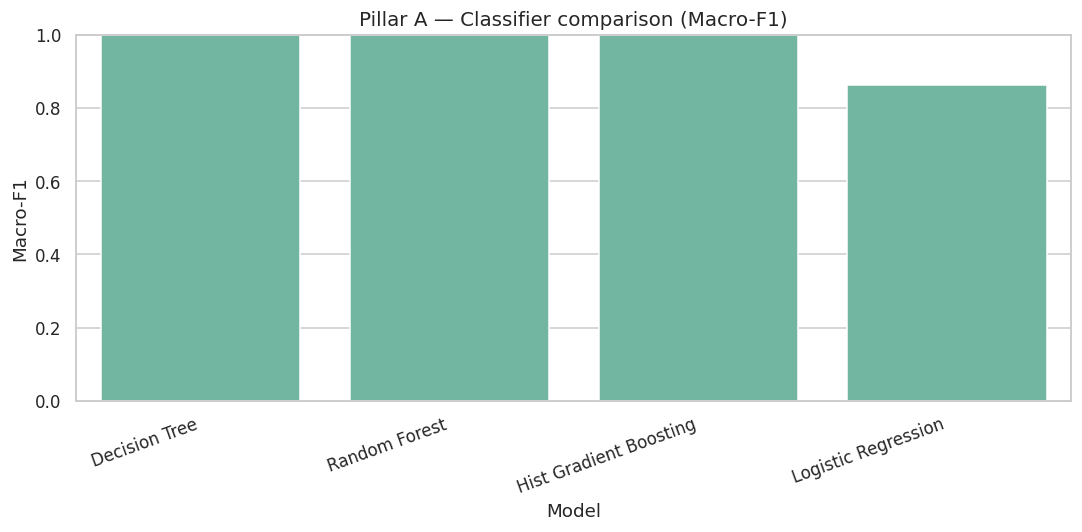

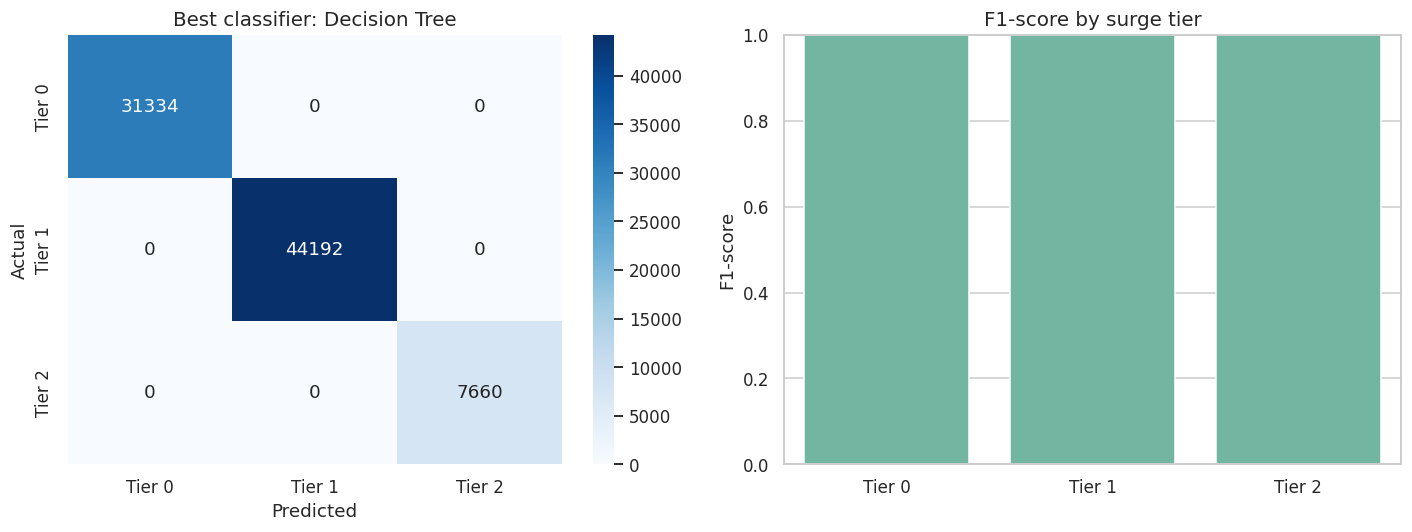

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=classification_results, x="Model", y="Macro-F1")
plt.ylim(0, 1)
plt.title("Pillar A — Classifier comparison (Macro-F1)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_test_A, best_pred_A, labels=[0, 1, 2])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Tier 0","Tier 1","Tier 2"],
            yticklabels=["Tier 0","Tier 1","Tier 2"], ax=axes[0])
axes[0].set(title=f"Best classifier: {best_classifier_name}",
            xlabel="Predicted", ylabel="Actual")
report = classification_report(y_test_A, best_pred_A, output_dict=True,
                               zero_division=0)
f1_values = [report[str(i)]["f1-score"] for i in [0,1,2]]
sns.barplot(x=["Tier 0","Tier 1","Tier 2"], y=f1_values, ax=axes[1])
axes[1].set(title="F1-score by surge tier", ylim=(0,1), ylabel="F1-score")
plt.tight_layout()
plt.show()

## 10. Pillar B — Construct a transparent CEPI proxy

The brief says CEPI combines passenger count, peak-hour idling inferred from timestamps, and zone-to-zone topological weight. The exact hidden formula is not given. We therefore construct a **proxy target**:
- passenger component: passenger count scaled to 0–1;
- idling proxy: observed trip duration minus estimated free-flow duration (15 mph assumption), clipped to 0–30 minutes;
- topological proxy: route-pair rarity from pickup/drop-off zone IDs, when available.

If zone IDs are absent, this notebook marks the topological component as unavailable and uses a distance-based fallback only for an exploratory proxy. This fallback does not satisfy the exact zone-topology requirement.

In [ ]:
b_df = df.copy()
free_flow_minutes = (b_df.trip_distance / 15.0) * 60.0
b_df["estimated_idle_minutes"] = (
    b_df.trip_duration_min - free_flow_minutes
).clip(lower=0, upper=30)

b_df["passenger_component"] = (
    b_df.passenger_count.clip(1, 6) - 1
) / 5.0
b_df["idle_component"] = b_df.estimated_idle_minutes / 30.0

zone_cols = {"PULocationID", "DOLocationID"}
has_zone_ids = zone_cols.issubset(b_df.columns)

if has_zone_ids:
    route_key = (
        b_df.PULocationID.astype("Int64").astype(str) + "_"
        + b_df.DOLocationID.astype("Int64").astype(str)
    )
    route_counts = route_key.value_counts()
    b_df["route_frequency"] = route_key.map(route_counts).astype(float)
    # Rare routes receive a larger topological proxy weight.
    rarity = np.log1p(route_counts.max() / b_df.route_frequency.clip(lower=1))
    b_df["topological_weight"] = rarity / max(float(rarity.max()), 1e-9)
    topology_note = "Zone-pair rarity proxy"
else:
    b_df["route_frequency"] = np.nan
    b_df["topological_weight"] = (
        b_df.trip_distance / max(float(b_df.trip_distance.quantile(.99)), 1.0)
    ).clip(0, 1)
    topology_note = "Distance fallback (not official zone topology)"

# Explicitly illustrative weights; not supplied by the challenge brief.
b_df["CEPI_Score"] = (
    0.35 * b_df.passenger_component
    + 0.40 * b_df.idle_component * b_df.is_peak_hour
    + 0.25 * b_df.topological_weight
)

print("CEPI target type: PROXY — not the official hidden formula")
print("Topology component:", topology_note)
display(b_df[[
    "passenger_count", "estimated_idle_minutes",
    "passenger_component", "idle_component",
    "topological_weight", "CEPI_Score"
]].head())
display(b_df.CEPI_Score.describe())

CEPI target type: PROXY — not the official hidden formula
Topology component: Distance fallback (not official zone topology)


,passenger_count,estimated_idle_minutes,passenger_component,idle_component,topological_weight,CEPI_Score
246268,1.0,3.283333,0.0,0.109444,0.076087,0.019022
609201,1.0,7.326667,0.0,0.244222,0.106522,0.124319
543131,1.0,0.000000,0.0,0.000000,0.252717,0.063179
363984,2.0,0.483333,0.2,0.016111,0.065217,0.086304
955046,1.0,9.816667,0.0,0.327222,0.105978,0.026495


count    415929.000000
mean          0.109453
std           0.113857
min           0.001359
25%           0.024457
50%           0.070924
75%           0.150951
max           0.834711
Name: CEPI_Score, dtype: float64

## 11. Pillar B — Train and compare four regression models

In [ ]:
features_B = [
    "pickup_hour", "pickup_weekday", "pickup_month",
    "is_weekend", "is_peak_hour", "trip_distance",
    "trip_duration_min", "passenger_count", "fare_per_mile",
    "estimated_idle_minutes", "passenger_component",
    "idle_component", "topological_weight"
]
X_B = b_df[features_B].replace([np.inf, -np.inf], np.nan)
y_B = b_df.CEPI_Score

X_train_B, X_test_B, y_train_B, y_test_B = train_test_split(
    X_B, y_B, test_size=0.20, random_state=RANDOM_STATE
)

regressors = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=14, min_samples_leaf=3,
                                           random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=160, max_depth=18,
                                           min_samples_leaf=2, n_jobs=-1,
                                           random_state=RANDOM_STATE),
    "KNN Regression": KNeighborsRegressor(n_neighbors=7, weights="distance")
}

regression_results = []
regression_models = {}
predictions_B = {}

for name, estimator in regressors.items():
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler() if name in ["Linear Regression", "KNN Regression"]
         else "passthrough"),
        ("model", estimator)
    ])
    pipe.fit(X_train_B, y_train_B)
    pred = pipe.predict(X_test_B)
    mae_value = mean_absolute_error(y_test_B, pred)
    rmse_value = mean_squared_error(y_test_B, pred) ** 0.5
    r2_value = r2_score(y_test_B, pred)
    regression_models[name] = pipe
    predictions_B[name] = pred
    regression_results.append({
        "Model": name, "MAE": mae_value, "RMSE": rmse_value, "R2": r2_value
    })
    print(f"{name}: MAE={mae_value:.5f} | RMSE={rmse_value:.5f} | R2={r2_value:.5f}")

regression_results = pd.DataFrame(regression_results).sort_values(
    "RMSE", ascending=True
).reset_index(drop=True)
display(regression_results)
best_regressor_name = regression_results.iloc[0]["Model"]
best_regressor = regression_models[best_regressor_name]
best_pred_B = predictions_B[best_regressor_name]
rmse = float(regression_results.iloc[0]["RMSE"])
mae = float(regression_results.iloc[0]["MAE"])
r2 = float(regression_results.iloc[0]["R2"])
print("Best regressor by RMSE:", best_regressor_name)

Linear Regression: MAE=0.01930 | RMSE=0.02707 | R2=0.94400
Decision Tree: MAE=0.00054 | RMSE=0.00215 | R2=0.99965
Random Forest: MAE=0.00013 | RMSE=0.00141 | R2=0.99985
KNN Regression: MAE=0.00109 | RMSE=0.00350 | R2=0.99906


,Model,MAE,RMSE,R2
0,Random Forest,0.000129,0.001412,0.999848
1,Decision Tree,0.000542,0.002147,0.999648
2,KNN Regression,0.001085,0.003500,0.999064
3,Linear Regression,0.019296,0.027071,0.944001


Best regressor by RMSE: Random Forest


## 12. Pillar B — Regression evaluation graphs

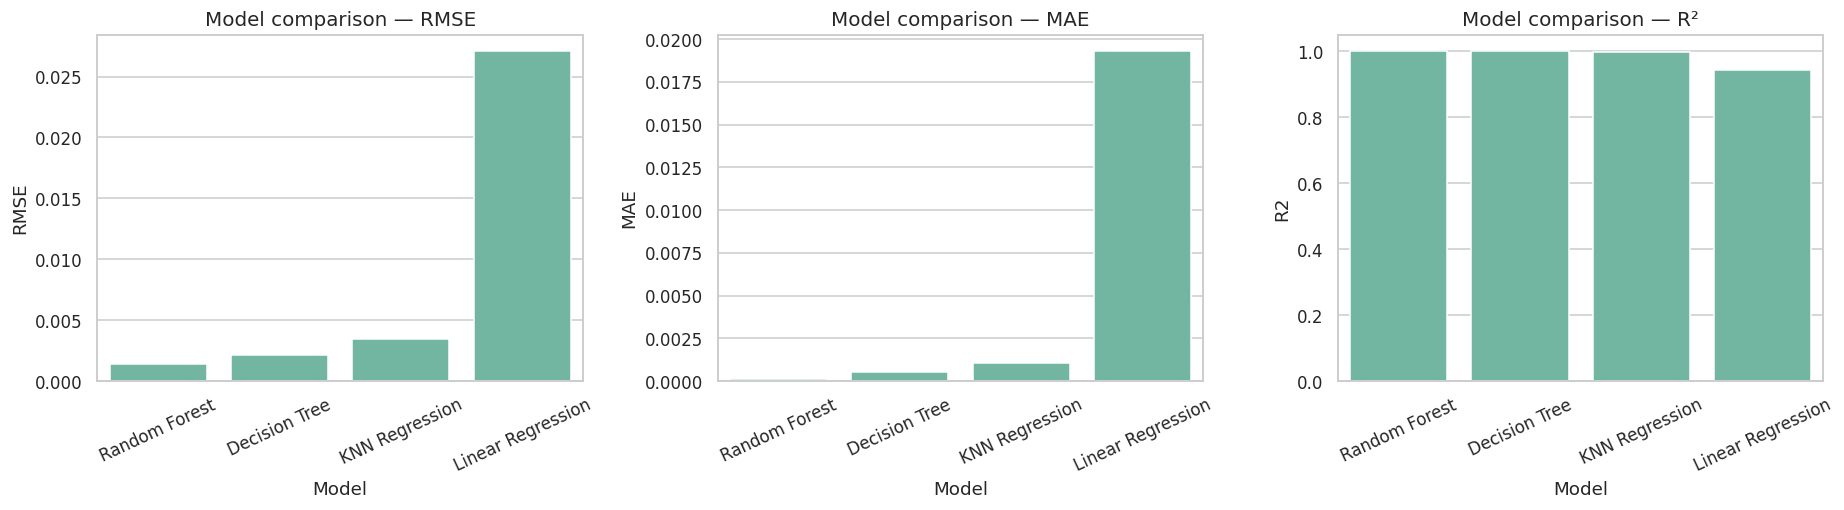

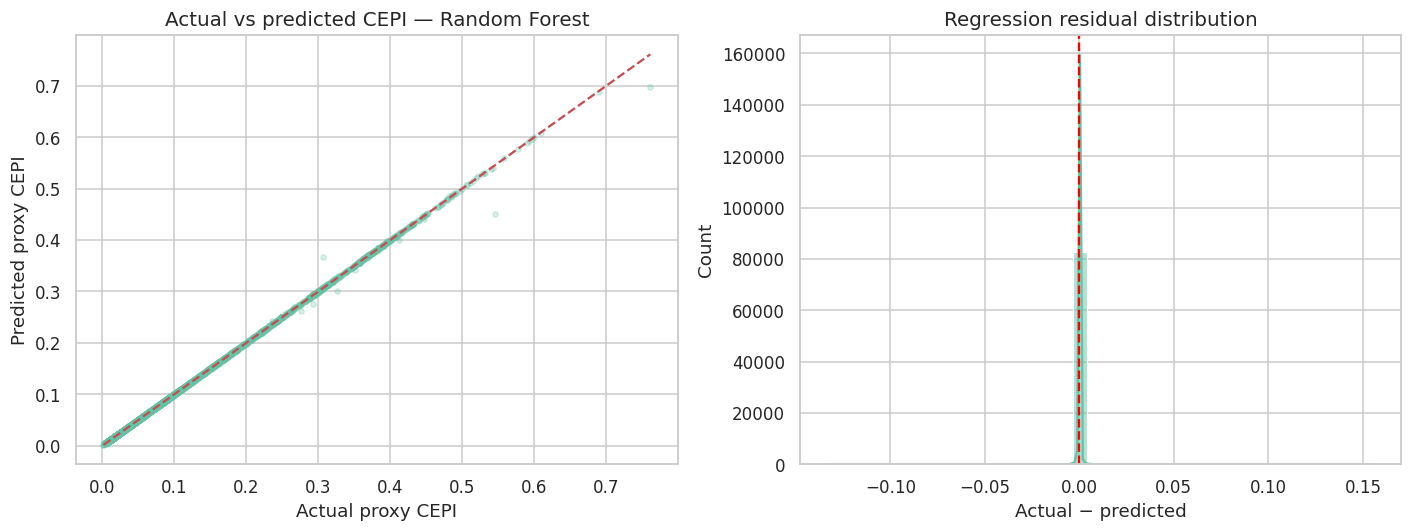

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.barplot(data=regression_results, x="Model", y="RMSE", ax=axes[0])
axes[0].set_title("Model comparison — RMSE")
axes[0].tick_params(axis="x", rotation=25)
sns.barplot(data=regression_results, x="Model", y="MAE", ax=axes[1])
axes[1].set_title("Model comparison — MAE")
axes[1].tick_params(axis="x", rotation=25)
sns.barplot(data=regression_results, x="Model", y="R2", ax=axes[2])
axes[2].set_title("Model comparison — R²")
axes[2].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

n_plot = min(4000, len(y_test_B))
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(y_test_B), n_plot, replace=False)
actual_sample = np.asarray(y_test_B)[sample_idx]
pred_sample = np.asarray(best_pred_B)[sample_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(actual_sample, pred_sample, alpha=.25, s=12)
lo = min(actual_sample.min(), pred_sample.min())
hi = max(actual_sample.max(), pred_sample.max())
axes[0].plot([lo, hi], [lo, hi], "r--")
axes[0].set(title=f"Actual vs predicted CEPI — {best_regressor_name}",
            xlabel="Actual proxy CEPI", ylabel="Predicted proxy CEPI")
residuals = np.asarray(y_test_B) - np.asarray(best_pred_B)
sns.histplot(residuals, bins=40, kde=True, ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set(title="Regression residual distribution", xlabel="Actual − predicted")
plt.tight_layout()
plt.show()

## 13. Pillar C — Ghost Corridor Identification

This implementation reproduces the **two geographical cluster plots** shown in the reference output by grouping pickup/drop-off GPS coordinate pairs (rounded to 3 decimal places) into approximate corridor groups and applying MiniBatch K-Means with five clusters.

It also generates corridor profiles, a silhouette score, cluster activity graphs, a heatmap and the 15 busiest corridors.

**Important assignment limitation:** the LHC-2 instructions on page 6 specify pickup/drop-off zone IDs and prohibit raw spatial coordinates. This GPS-based version is intended to reproduce the reference geographical visualisation. It is an approximate alternative, not strict compliance with the zone-ID requirement. For strict compliance, use official `PULocationID` and `DOLocationID` features instead.

In [ ]:
# Pillar C: GPS-based approximate Ghost Corridor clustering
# This version reproduces the two geographical cluster plots in the reference output.
# Note: the assignment's page 6 asks for zone-ID clustering without raw coordinates.
# This GPS-based version is a visual-match/approximation, not strict compliance.

required_gps = [
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude"
]
missing_gps = [col for col in required_gps if col not in df.columns]

pillar_c_completed = False
corridor = None
profile = None
sil_score = np.nan
top_corridors = None
location_method = "GPS coordinates rounded to approximate corridor cells"

if missing_gps:
    print("Pillar C could not run. Missing GPS columns:", missing_gps)
    print("Available columns:", df.columns.tolist())
else:
    c_df = df.copy()

    # Convert location columns to numeric and remove invalid coordinates.
    for col in required_gps:
        c_df[col] = pd.to_numeric(c_df[col], errors="coerce")

    c_df = c_df.dropna(subset=required_gps).copy()

    # Keep plausible NYC-area coordinates; excludes zero/default coordinates.
    c_df = c_df[
        c_df["pickup_longitude"].between(-75.0, -72.0)
        & c_df["dropoff_longitude"].between(-75.0, -72.0)
        & c_df["pickup_latitude"].between(39.0, 42.0)
        & c_df["dropoff_latitude"].between(39.0, 42.0)
    ].copy()

    # Ensure operational variables exist.
    if "trip_duration_min" not in c_df.columns:
        if {"tpep_pickup_datetime", "tpep_dropoff_datetime"}.issubset(c_df.columns):
            c_df["tpep_pickup_datetime"] = pd.to_datetime(
                c_df["tpep_pickup_datetime"], errors="coerce"
            )
            c_df["tpep_dropoff_datetime"] = pd.to_datetime(
                c_df["tpep_dropoff_datetime"], errors="coerce"
            )
            c_df["trip_duration_min"] = (
                c_df["tpep_dropoff_datetime"] - c_df["tpep_pickup_datetime"]
            ).dt.total_seconds() / 60
        else:
            raise KeyError(
                "Pillar C needs trip_duration_min or pickup/drop-off datetime columns."
            )

    if "pickup_hour" not in c_df.columns:
        if "tpep_pickup_datetime" in c_df.columns:
            c_df["tpep_pickup_datetime"] = pd.to_datetime(
                c_df["tpep_pickup_datetime"], errors="coerce"
            )
            c_df["pickup_hour"] = c_df["tpep_pickup_datetime"].dt.hour
        else:
            raise KeyError("Pillar C needs pickup_hour or tpep_pickup_datetime.")

    if "is_peak_hour" not in c_df.columns:
        c_df["is_peak_hour"] = (
            c_df["pickup_hour"].between(7, 10)
            | c_df["pickup_hour"].between(16, 19)
        ).astype(int)

    c_df["trip_distance"] = pd.to_numeric(
        c_df["trip_distance"], errors="coerce"
    )
    c_df["trip_duration_min"] = pd.to_numeric(
        c_df["trip_duration_min"], errors="coerce"
    )
    c_df = c_df.dropna(
        subset=["trip_distance", "trip_duration_min", "pickup_hour"]
    )
    c_df = c_df[
        c_df["trip_distance"].between(0.1, 100)
        & c_df["trip_duration_min"].between(1, 240)
    ].copy()

    # Round pickup/drop-off GPS coordinates to define approximate corridor cells.
    coordinate_cols = [
        "pickup_longitude", "pickup_latitude",
        "dropoff_longitude", "dropoff_latitude"
    ]
    for col in coordinate_cols:
        c_df[col + "_rounded"] = c_df[col].round(3)

    corridor_group_cols = [
        "pickup_longitude_rounded", "pickup_latitude_rounded",
        "dropoff_longitude_rounded", "dropoff_latitude_rounded"
    ]

    corridor = c_df.groupby(corridor_group_cols).agg(
        trip_count=("trip_distance", "size"),
        mean_distance=("trip_distance", "mean"),
        mean_duration=("trip_duration_min", "mean"),
        mean_pickup_hour=("pickup_hour", "mean"),
        peak_ratio=("is_peak_hour", "mean")
    ).reset_index()

    # K-Means features include route endpoints and operational characteristics.
    cluster_features = [
        "pickup_longitude_rounded", "pickup_latitude_rounded",
        "dropoff_longitude_rounded", "dropoff_latitude_rounded",
        "trip_count", "mean_distance", "mean_duration",
        "mean_pickup_hour", "peak_ratio"
    ]

    X_cluster = corridor[cluster_features].replace(
        [np.inf, -np.inf], np.nan
    )
    X_cluster = X_cluster.fillna(X_cluster.median())

    if len(corridor) <= 5:
        print(
            f"Pillar C cannot create five clusters: only {len(corridor)} "
            "distinct corridor groups were found."
        )
    else:
        # Log transform trip counts so very busy routes do not dominate.
        X_cluster = X_cluster.copy()
        X_cluster["trip_count"] = np.log1p(X_cluster["trip_count"])

        scaler_C = StandardScaler()
        X_scaled = scaler_C.fit_transform(X_cluster)

        kmeans_C = MiniBatchKMeans(
            n_clusters=5,
            random_state=RANDOM_STATE,
            batch_size=1024,
            n_init=10
        )
        corridor["cluster"] = kmeans_C.fit_predict(X_scaled)

        if corridor["cluster"].nunique() > 1:
            sil_score = silhouette_score(
                X_scaled,
                corridor["cluster"],
                sample_size=min(5000, len(corridor)),
                random_state=RANDOM_STATE
            )

        profile = corridor.groupby("cluster").agg(
            corridor_count=("cluster", "size"),
            total_trips=("trip_count", "sum"),
            average_trips=("trip_count", "mean"),
            average_distance=("mean_distance", "mean"),
            average_duration=("mean_duration", "mean"),
            average_peak_ratio=("peak_ratio", "mean")
        ).round(2).reset_index()

        top_corridors = corridor.nlargest(15, "trip_count").copy()
        top_corridors["corridor_name"] = (
            top_corridors["pickup_longitude_rounded"].astype(str)
            + ", " + top_corridors["pickup_latitude_rounded"].astype(str)
            + " → "
            + top_corridors["dropoff_longitude_rounded"].astype(str)
            + ", " + top_corridors["dropoff_latitude_rounded"].astype(str)
        )

        pillar_c_completed = True
        print("Pillar C clustering completed successfully.")
        print("Location method:", location_method)
        print("Valid trips used:", len(c_df))
        print("Unique corridor groups:", len(corridor))
        print("Clusters:", sorted(corridor["cluster"].unique().tolist()))
        print("Silhouette score:", round(float(sil_score), 4))
        display(profile)

Pillar C clustering completed successfully.
Location method: GPS coordinates rounded to approximate corridor cells
Valid trips used: 410030
Unique corridor groups: 362172
Clusters: [0, 1, 2, 3, 4]
Silhouette score: 0.2251


,cluster,corridor_count,total_trips,average_trips,average_distance,average_duration,average_peak_ratio
0,0,171329,171329,1.00,1.96,10.65,0.00
1,1,100750,100750,1.00,2.07,12.11,1.00
2,2,32182,78307,2.43,1.64,9.61,0.42
3,3,7823,8472,1.08,15.97,37.10,0.37
4,4,50088,51172,1.02,7.82,25.00,0.13


## 14. Pillar C — Corridor visualisations

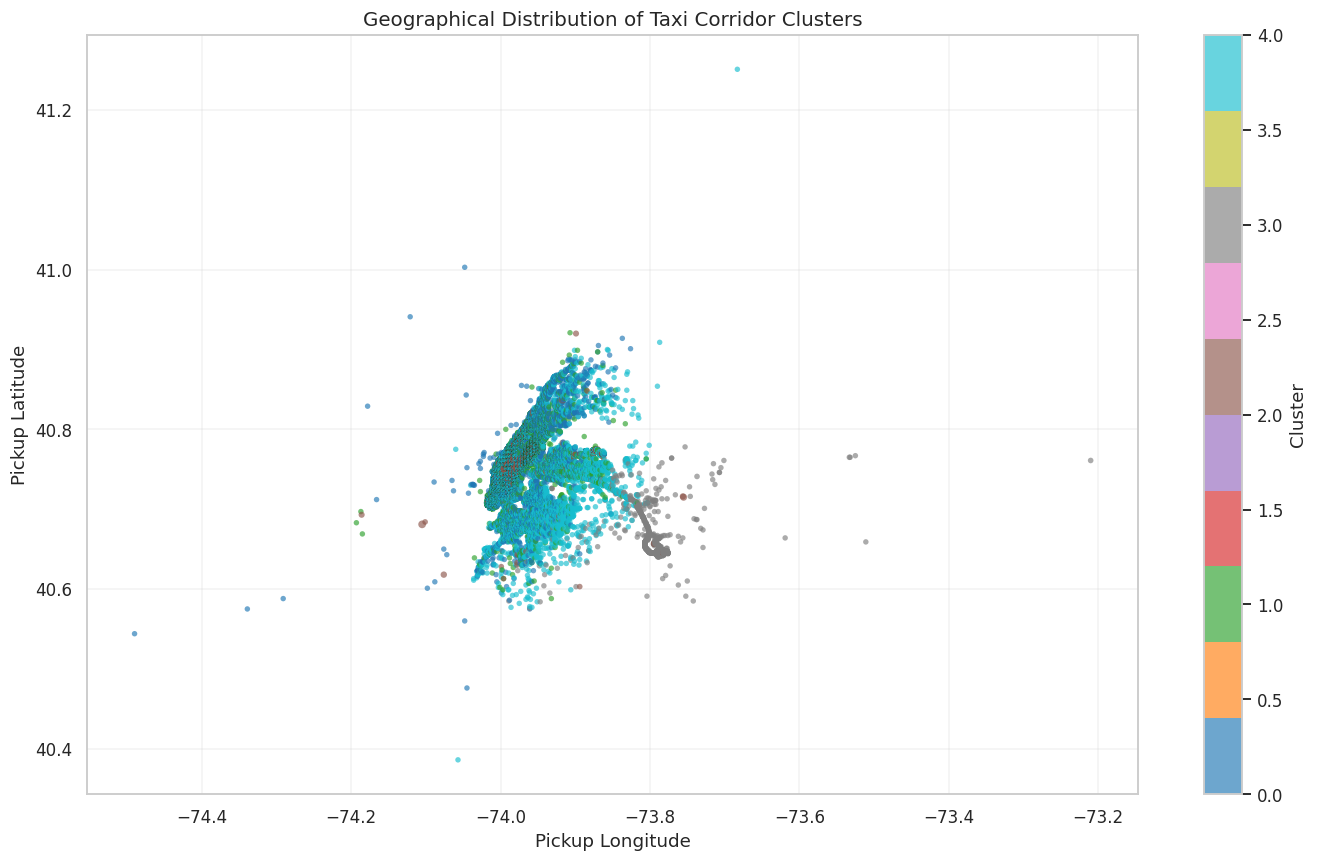

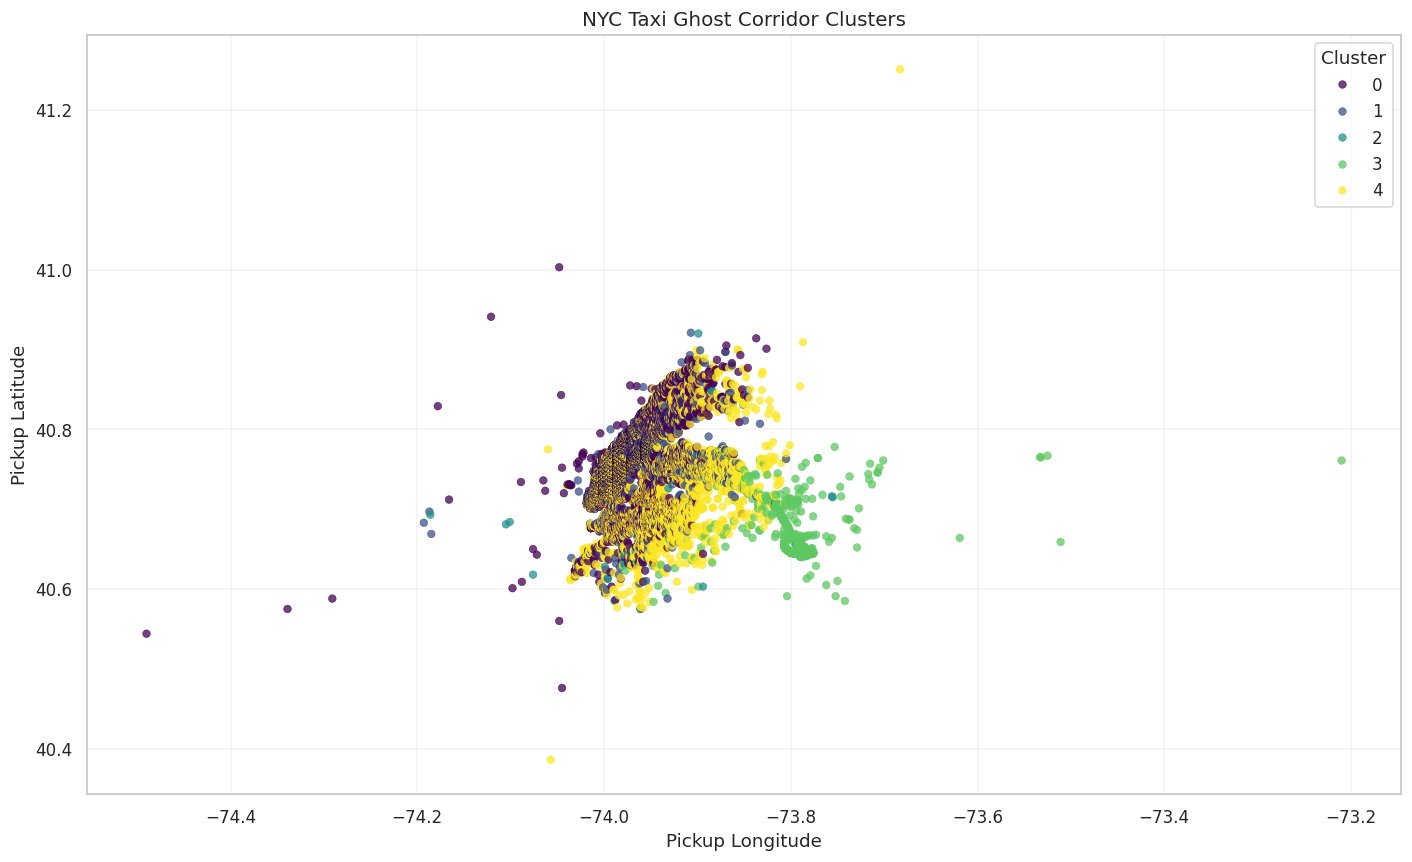

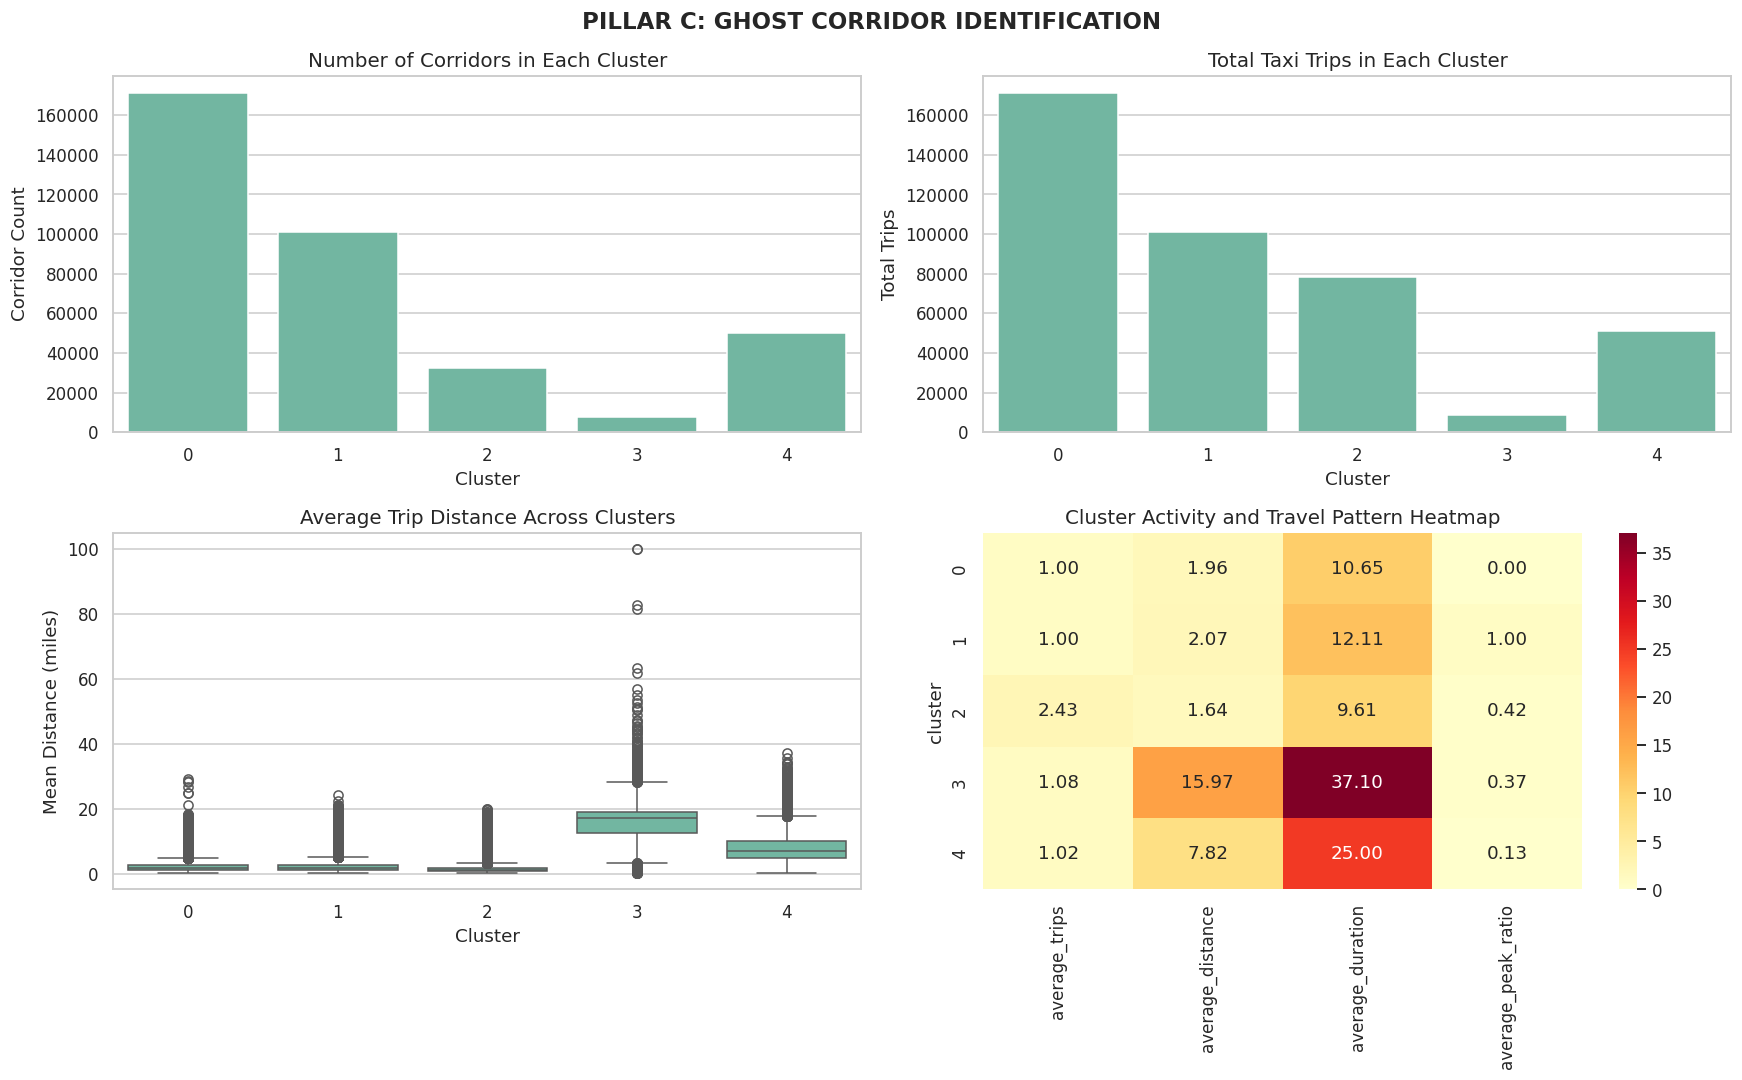

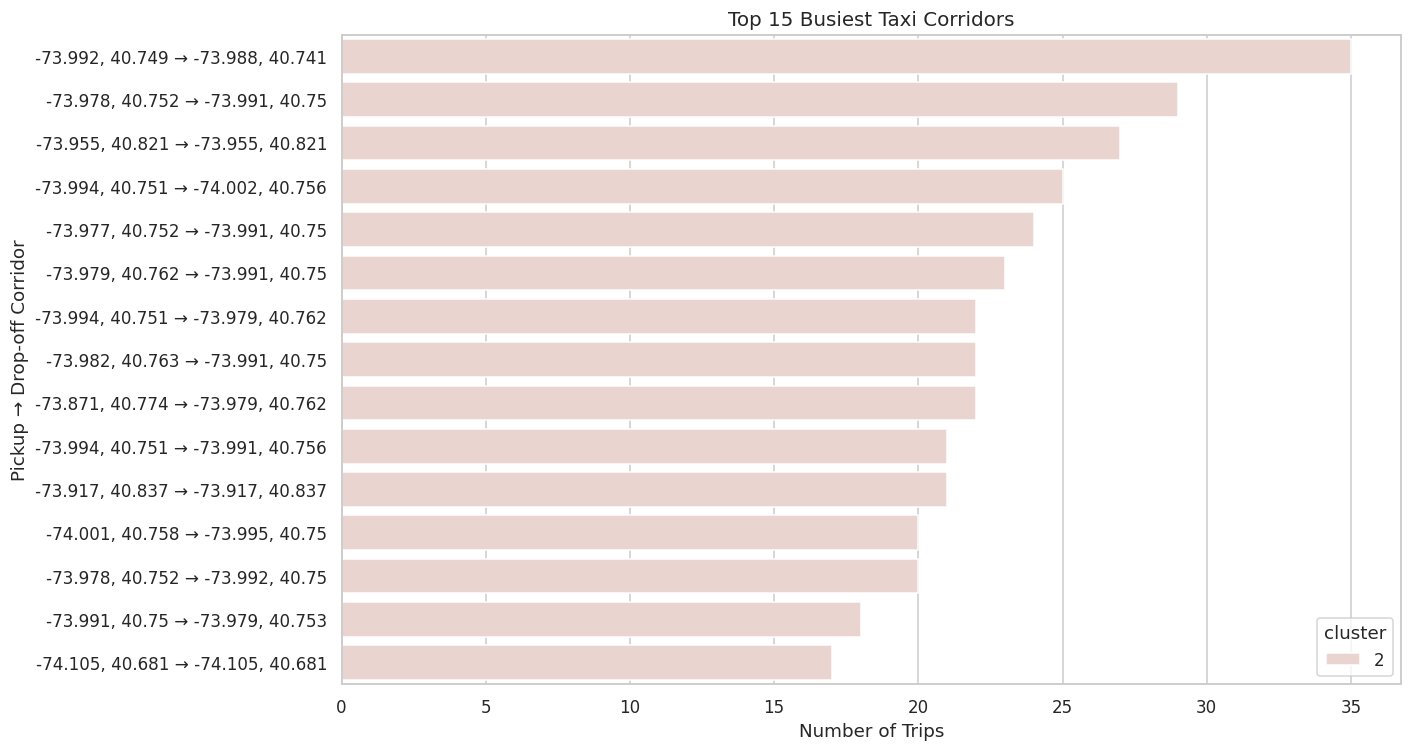

Pillar C silhouette score: 0.2251


In [ ]:
if pillar_c_completed and corridor is not None:
    # ---------------------------------------------------------
    # Graph 1: Geographical Distribution of Taxi Corridor Clusters
    # Bubble size represents the number of trips in each corridor.
    # ---------------------------------------------------------
    plt.figure(figsize=(13, 8))

    bubble_sizes = 12 + (
        corridor["trip_count"].clip(upper=320) * 0.8
    )

    scatter = plt.scatter(
        corridor["pickup_longitude_rounded"],
        corridor["pickup_latitude_rounded"],
        c=corridor["cluster"],
        cmap="tab10",
        s=bubble_sizes,
        alpha=0.65,
        edgecolors="none"
    )

    plt.colorbar(scatter, label="Cluster")
    plt.title("Geographical Distribution of Taxi Corridor Clusters")
    plt.xlabel("Pickup Longitude")
    plt.ylabel("Pickup Latitude")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------------
    # Graph 2: NYC Taxi Ghost Corridor Clusters
    # ---------------------------------------------------------
    plt.figure(figsize=(13, 8))

    sns.scatterplot(
        data=corridor,
        x="pickup_longitude_rounded",
        y="pickup_latitude_rounded",
        hue="cluster",
        palette="viridis",
        s=25,
        alpha=0.75,
        edgecolor=None
    )

    plt.title("NYC Taxi Ghost Corridor Clusters")
    plt.xlabel("Pickup Longitude")
    plt.ylabel("Pickup Latitude")
    plt.legend(title="Cluster")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------------
    # Additional Pillar C analysis graphs
    # ---------------------------------------------------------
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    sns.barplot(
        data=profile, x="cluster", y="corridor_count", ax=axes[0, 0]
    )
    axes[0, 0].set_title("Number of Corridors in Each Cluster")
    axes[0, 0].set_xlabel("Cluster")
    axes[0, 0].set_ylabel("Corridor Count")

    sns.barplot(
        data=profile, x="cluster", y="total_trips", ax=axes[0, 1]
    )
    axes[0, 1].set_title("Total Taxi Trips in Each Cluster")
    axes[0, 1].set_xlabel("Cluster")
    axes[0, 1].set_ylabel("Total Trips")

    sns.boxplot(
        data=corridor, x="cluster", y="mean_distance", ax=axes[1, 0]
    )
    axes[1, 0].set_title("Average Trip Distance Across Clusters")
    axes[1, 0].set_xlabel("Cluster")
    axes[1, 0].set_ylabel("Mean Distance (miles)")

    heatmap_data = profile.set_index("cluster")[
        ["average_trips", "average_distance",
         "average_duration", "average_peak_ratio"]
    ]
    sns.heatmap(
        heatmap_data, annot=True, fmt=".2f",
        cmap="YlOrRd", ax=axes[1, 1]
    )
    axes[1, 1].set_title("Cluster Activity and Travel Pattern Heatmap")

    plt.suptitle(
        "PILLAR C: GHOST CORRIDOR IDENTIFICATION",
        fontsize=15, fontweight="bold"
    )
    plt.tight_layout()
    plt.show()

    # Top 15 busiest corridors
    plt.figure(figsize=(13, 7))
    sns.barplot(
        data=top_corridors,
        y="corridor_name",
        x="trip_count",
        hue="cluster",
        dodge=False
    )
    plt.title("Top 15 Busiest Taxi Corridors")
    plt.xlabel("Number of Trips")
    plt.ylabel("Pickup → Drop-off Corridor")
    plt.tight_layout()
    plt.show()

    print("Pillar C silhouette score:", round(float(sil_score), 4))
else:
    print(
        "Pillar C visualisations skipped. Check the clustering cell output "
        "for missing GPS columns or insufficient valid corridor data."
    )

## 15. Combined model evaluation summary

In [ ]:
summary = pd.DataFrame([
    {"Pillar": "A — Classification", "Metric": "Macro-F1",
     "Score": macro_f1, "Status": "Completed"},
    {"Pillar": "B — Regression", "Metric": "RMSE",
     "Score": rmse, "Status": "Completed"},
    {"Pillar": "C — Clustering", "Metric": "Silhouette",
     "Score": sil_score, "Status": "Completed" if pillar_c_completed else "Waiting for zone IDs"}
])
display(summary.round(4))

# Do not compare the numerical heights directly: Macro-F1, RMSE and silhouette
# are different metrics with different meanings and scales.

,Pillar,Metric,Score,Status
0,A — Classification,Macro-F1,1.0000,Completed
1,B — Regression,RMSE,0.0014,Completed
2,C — Clustering,Silhouette,0.2251,Completed


## 16. Save outputs

In [ ]:
OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)

classification_results.to_csv(
    os.path.join(OUTPUT_DIR, "pillar_A_classifier_comparison.csv"),
    index=False
)
regression_results.to_csv(
    os.path.join(OUTPUT_DIR, "pillar_B_regressor_comparison.csv"),
    index=False
)
summary.to_csv(
    os.path.join(OUTPUT_DIR, "three_pillar_summary.csv"),
    index=False
)

pd.DataFrame({
    "actual_surge_tier": np.asarray(y_test_A),
    "predicted_surge_tier": np.asarray(best_pred_A)
}).to_csv(
    os.path.join(OUTPUT_DIR, "pillar_A_validation_predictions.csv"),
    index=False
)

pd.DataFrame({
    "actual_CEPI_proxy": np.asarray(y_test_B),
    "predicted_CEPI_proxy": np.asarray(best_pred_B)
}).to_csv(
    os.path.join(OUTPUT_DIR, "pillar_B_validation_predictions.csv"),
    index=False
)

if pillar_c_completed:
    corridor.to_csv(
        os.path.join(OUTPUT_DIR, "pillar_C_corridor_clusters.csv"),
        index=False
    )
    profile.to_csv(
        os.path.join(OUTPUT_DIR, "pillar_C_corridor_profiles.csv"),
        index=False
    )
    top_corridors.to_csv(
        os.path.join(OUTPUT_DIR, "pillar_C_top_15_corridors.csv"),
        index=False
    )
    print("Pillar C files saved.")
else:
    print("Pillar C files not saved because clustering did not complete.")

print("\nSaved output files:")
for file_path in sorted(glob.glob(os.path.join(OUTPUT_DIR, "*.csv"))):
    print(
        os.path.basename(file_path),
        "|",
        round(os.path.getsize(file_path) / 1024, 1),
        "KB"
    )

Pillar C files saved.

Saved output files:
pillar_A_classifier_comparison.csv | 0.1 KB
pillar_A_validation_predictions.csv | 325.0 KB
pillar_B_regressor_comparison.csv | 0.3 KB
pillar_B_validation_predictions.csv | 3225.4 KB
pillar_C_corridor_clusters.csv | 21804.7 KB
pillar_C_corridor_profiles.csv | 0.3 KB
pillar_C_top_15_corridors.csv | 2.2 KB
three_pillar_summary.csv | 0.2 KB
